In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.impute import SimpleImputer

In [ ]:
# Load the dataset
df = pd.read_csv("/uber.csv")

# view dataset
print(df)

        Unnamed: 0                            key  fare_amount  \
0         24238194    2015-05-07 19:52:06.0000003          7.5   
1         27835199    2009-07-17 20:04:56.0000002          7.7   
2         44984355   2009-08-24 21:45:00.00000061         12.9   
3         25894730    2009-06-26 08:22:21.0000001          5.3   
4         17610152  2014-08-28 17:47:00.000000188         16.0   
...            ...                            ...          ...   
199995    42598914   2012-10-28 10:49:00.00000053          3.0   
199996    16382965    2014-03-14 01:09:00.0000008          7.5   
199997    27804658   2009-06-29 00:42:00.00000078         30.9   
199998    20259894    2015-05-20 14:56:25.0000004         14.5   
199999    11951496   2010-05-15 04:08:00.00000076         14.1   

                pickup_datetime  pickup_longitude  pickup_latitude  \
0       2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1       2009-07-17 20:04:56 UTC        -73.994355        40.728225 

In [ ]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
# print(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
# print(df['hour'])
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
# print(df['day_of_week'])

In [ ]:
# check datasets for more columns we added 'hour' and 'day_of_week' column
print(df)

        Unnamed: 0                            key  fare_amount  \
0         24238194    2015-05-07 19:52:06.0000003          7.5   
1         27835199    2009-07-17 20:04:56.0000002          7.7   
2         44984355   2009-08-24 21:45:00.00000061         12.9   
3         25894730    2009-06-26 08:22:21.0000001          5.3   
4         17610152  2014-08-28 17:47:00.000000188         16.0   
...            ...                            ...          ...   
199995    42598914   2012-10-28 10:49:00.00000053          3.0   
199996    16382965    2014-03-14 01:09:00.0000008          7.5   
199997    27804658   2009-06-29 00:42:00.00000078         30.9   
199998    20259894    2015-05-20 14:56:25.0000004         14.5   
199999    11951496   2010-05-15 04:08:00.00000076         14.1   

                 pickup_datetime  pickup_longitude  pickup_latitude  \
0      2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1      2009-07-17 20:04:56+00:00        -73.994355        40.7282

In [ ]:
# Drop unnecessary columns
df = df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'])

In [ ]:
# check datasets for removal of columns we removed 'first_column with no name', 'key' and 'pickup_datetime' column
print(df)

        fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0               7.5        -73.999817        40.738354         -73.999512   
1               7.7        -73.994355        40.728225         -73.994710   
2              12.9        -74.005043        40.740770         -73.962565   
3               5.3        -73.976124        40.790844         -73.965316   
4              16.0        -73.925023        40.744085         -73.973082   
...             ...               ...              ...                ...   
199995          3.0        -73.987042        40.739367         -73.986525   
199996          7.5        -73.984722        40.736837         -74.006672   
199997         30.9        -73.986017        40.756487         -73.858957   
199998         14.5        -73.997124        40.725452         -73.983215   
199999         14.1        -73.984395        40.720077         -73.985508   

        dropoff_latitude  passenger_count  hour  day_of_week  
0           

In [ ]:
# Handle missing values
imputer = SimpleImputer(strategy='mean')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

In [ ]:
# Identify outliers using IQR method
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

outliers = ((df < (Q1 - 1.5 * IQR)) |
            (df > (Q3 + 1.5 * IQR)))

print("Number of outliers in each column:")
print(outliers.sum())

Number of outliers in each column:
fare_amount          17167
pickup_longitude     13559
pickup_latitude       9424
dropoff_longitude    14200
dropoff_latitude     12145
passenger_count      22557
hour                     0
day_of_week              0
dtype: int64


In [ ]:
# Check correlation
correlation = df_imputed.corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.010457        -0.008481   
pickup_longitude      0.010457          1.000000        -0.816461   
pickup_latitude      -0.008481         -0.816461         1.000000   
dropoff_longitude     0.008986          0.833026        -0.774787   
dropoff_latitude     -0.011014         -0.846324         0.702367   
passenger_count       0.010150         -0.000414        -0.001560   
hour                 -0.021473          0.002433        -0.003822   
day_of_week           0.007501          0.000825        -0.002455   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                 0.008986         -0.011014         0.010150   
pickup_longitude            0.833026         -0.846324        -0.000414   
pickup_latitude            -0.774787          0.702367        -0.001560   
dropoff_longitude           1.000000         -0.917010    

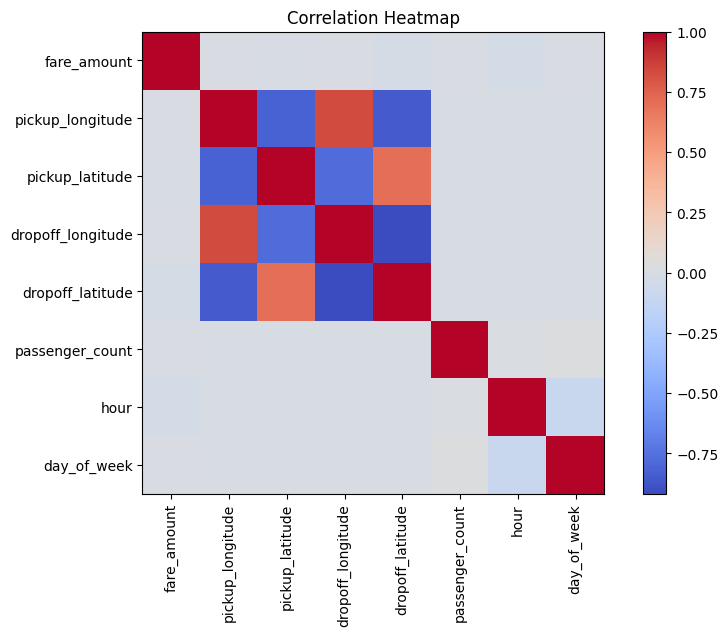

In [ ]:
# Visualize correlation using heatmap
plt.figure(figsize=(10, 6))
plt.imshow(correlation, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Split the data into features (X) and target (y)
X = df_imputed.drop(columns=['fare_amount'])  # create new dataset ignoring 'fare_amount' column
y = df_imputed['fare_amount']  # create a series of only 'fare_amount' column

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Standardize the features (scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Implement Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

In [ ]:
# Implement Ridge Regression
ridge_model = Ridge(alpha=1.0)  # You can experiment with different alpha values
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

In [ ]:
# Implement Lasso Regression
lasso_model = Lasso(alpha=0.1)  # You can experiment with different alpha values
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

In [ ]:
# Evaluate the models
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} - R2 Score: {r2:.4f}, RMSE: {rmse:.2f}")

In [ ]:
evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")

Linear Regression - R2 Score: 0.0007, RMSE: 10.31
Ridge Regression - R2 Score: 0.0007, RMSE: 10.31
Lasso Regression - R2 Score: 0.0003, RMSE: 10.31
